In [14]:
#DMV-6 : Retail Sales - Analyzing Sales Performance by Region in a Retail Company

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [15]:
path = kagglehub.dataset_download("vivek468/superstore-dataset-final")
file = next(Path(path).rglob("*.csv"))

Using Colab cache for faster access to the 'superstore-dataset-final' dataset.


In [16]:
df = pd.read_csv(file, encoding="latin1")

In [17]:
print("First 5 Rows:")
display(df.head())

First 5 Rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [18]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [19]:
# Data Cleaning
df = df.drop_duplicates()
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df = df.dropna(subset=["Region", "Sales"])

In [20]:
# Regional Sales Aggregation
regional_sales = df.groupby("Region")["Sales"].agg(
    ["sum", "mean", "count"]
).sort_values("sum", ascending=False)

print("Regional Sales Performance:")
print(regional_sales)

Regional Sales Performance:
                 sum        mean  count
Region                                 
West     725457.8245  226.493233   3203
East     678781.2400  238.336110   2848
Central  501239.8908  215.772661   2323
South    391721.9050  241.803645   1620


In [21]:
# Identify Top Performing Region
print("Top Performing Region:", regional_sales.index[0])
print("Highest Total Sales:", regional_sales["sum"].iloc[0])

Top Performing Region: West
Highest Total Sales: 725457.8245


In [22]:
# Category-wise Sales by Region
category_sales = df.groupby(
    ["Region", "Category"]
)["Sales"].sum().unstack(fill_value=0)

print("Category-wise Regional Sales:")
print(category_sales)

Category-wise Regional Sales:
Category    Furniture  Office Supplies  Technology
Region                                            
Central   163797.1638       167026.415  170416.312
East      208291.2040       205516.055  264973.981
South     117298.6840       125651.313  148771.908
West      252612.7435       220853.249  251991.832


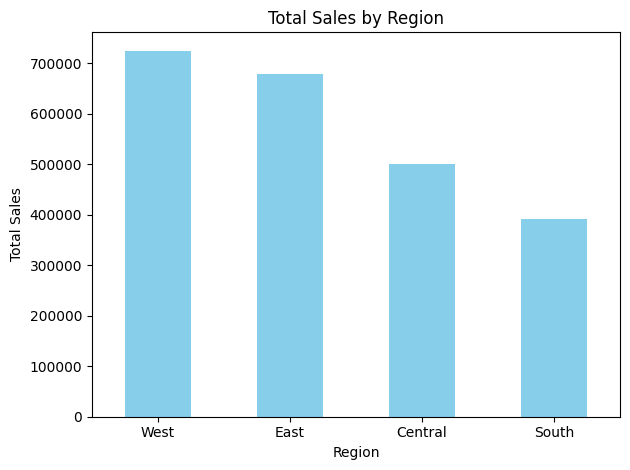

In [23]:
# Visualization - Regional Sales
regional_sales["sum"].plot(kind="bar", color="skyblue")
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

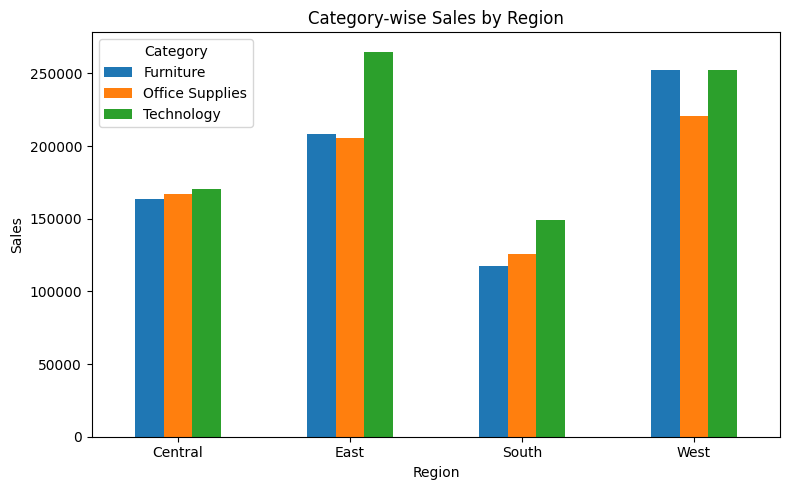

In [24]:
# Visualization - Category-wise Sales
category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Category-wise Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

regional_sales.to_csv("regional_sales_summary.csv")